In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [41]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule
from torch_geometric.utils.convert import from_networkx
from einops import rearrange
from scipy.spatial import ConvexHull
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.hypergraph_utils import get_cliques_planar
from scipy.spatial import Voronoi, voronoi_plot_2d
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
adata_subset = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad", backed='r')

In [5]:
coordinates = adata_subset.obsm['X_selected_cell_spatial_tiled']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])

In [42]:
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

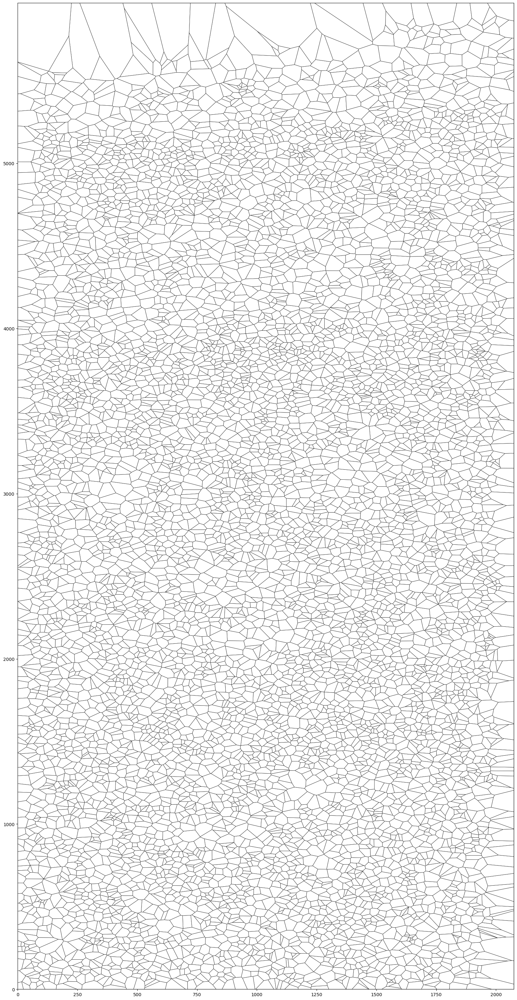

In [49]:
plt.figure(figsize=(20, 40))
plot_voronoi_polygons(G)
plt.axes().set_aspect('equal')
plt.axis('off')
plt.show()

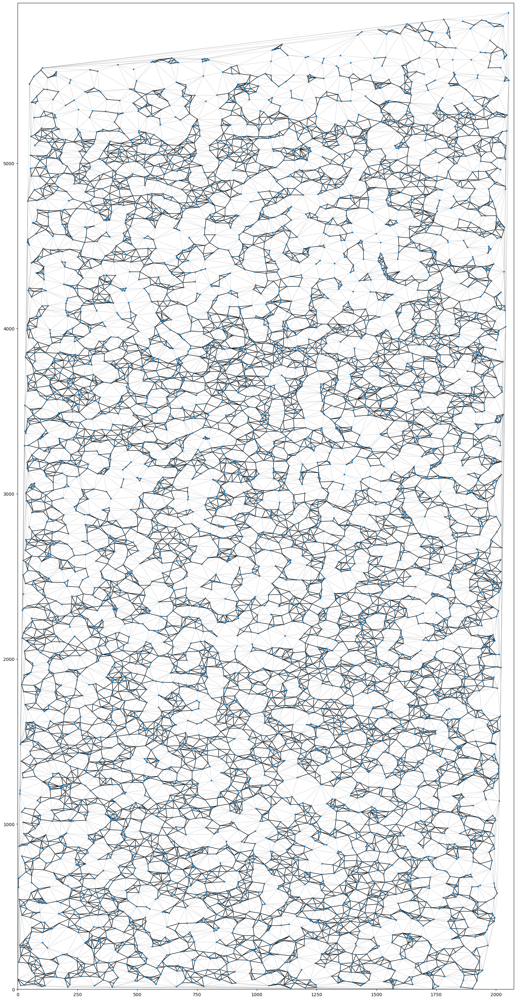

In [50]:
plt.figure(figsize=(20, 40))
plot_graph(G)
plt.axes().set_aspect('equal')
plt.axis('off')
plt.show()

In [61]:
num_hops = 1
X_cmbn = adata_subset[:,:].X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, num_hops)
dataset = HGDataset(original_dataset, to_hg_func)

Converting to hypergraph data: 100%|██████████| 1/1 [00:08<00:00,  8.91s/it]


In [63]:
eidf = get_hyperedge_pos_df(dataset[0], coordinates)

In [64]:
enh = compute_enlarged_hulls(eidf)

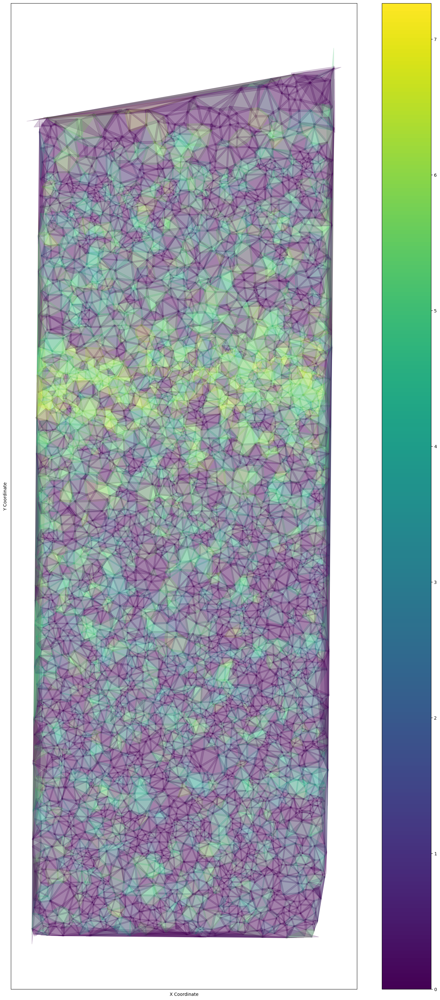

In [77]:
fig = plt.figure(figsize=(20, 40))
ax = fig.add_subplot(111)
ax = plot_hulls(enh, X_cmbn[:, 0], alpha=0.2, ax=ax)
ax.set_aspect('equal')
plt.show()

In [ ]:
assert False


In [7]:
vor = Voronoi(coordinates)

<Figure size 10000x10000 with 0 Axes>

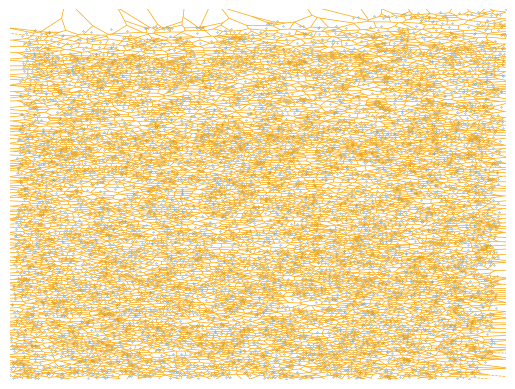

In [24]:
plt.figure(figsize=(100, 100), dpi=100)
voronoi_plot_2d(vor, show_vertices=False, line_colors='orange',
    line_width=.5, line_alpha=1, point_size=.5)
plt.xlim(coordinates[:, 0].min(), coordinates[:, 0].max())
plt.ylim(coordinates[:, 1].min(), coordinates[:, 1].max())
plt.axis('off')
plt.show()

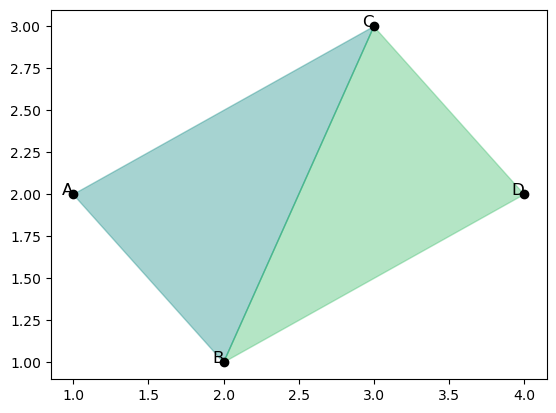

In [52]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from itertools import combinations
import numpy as np

# Sample nodes and hyperedges
nodes = {'A': (1, 2), 'B': (2, 1), 'C': (3, 3), 'D': (4, 2)}
hyperedges = {('A', 'B', 'C'): 0.5, ('B', 'C', 'D'): 0.7, ('A'):0.2, ('B','C'): 0.6}  # with values

# Setup plot
fig, ax = plt.subplots()

# Plot nodes
for node, pos in nodes.items():
    ax.plot(*pos, marker='o', color='black')
    ax.text(*pos, node, fontsize=12, ha='right')

# Plot hyperedges
for edge, value in hyperedges.items():
    poly_points = [nodes[n] for n in edge]
    polygon = plt.Polygon(poly_points, alpha=0.4, color=plt.cm.viridis(value))
    ax.add_patch(polygon)

# Show plot
plt.show()


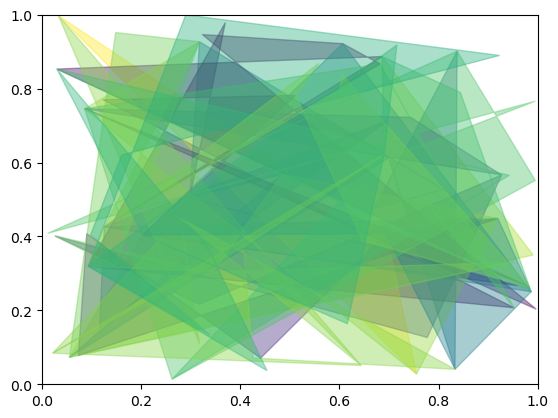

In [58]:
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations

# Generate 100 nodes
num_nodes = 100
nodes = {f'N{i}': (np.random.rand(), np.random.rand()) for i in range(num_nodes)}

# Define some hyperedges (example: random selection of nodes)
num_hyperedges = 20
hyperedges = {tuple(np.random.choice(list(nodes.keys()), size=np.random.randint(3, 10), replace=False)): np.random.rand() for _ in range(num_hyperedges)}

# Plotting (similar to the previous example)
fig, ax = plt.subplots()
# for node, pos in nodes.items():
#     ax.plot(*pos, marker='', color='black')
    # ax.text(*pos, node, fontsize=6, ha='right')

for edge, value in hyperedges.items():
    poly_points = [nodes[n] for n in edge]
    polygon = plt.Polygon(poly_points, alpha=0.4, color=plt.cm.viridis(value))
    ax.add_patch(polygon)

plt.show()
